# AulaSense — Versión C: Adaptadores y estrategias para sensores

**Universidad Politécnica de Querétaro** · Ingeniería en Datos e Inteligencia Artificial
**Materia:** Ingeniería en Software · **Actividad 1 – Segundo parcial:** Análisis y mejora del diseño de software
**Docente:** Omar Gómez Olvera · **Grupo:** IDIA211

| Dato | Valor |
|---|---|
| Integrante | Olguín Narváez Javier Yael |
| Propuesta | Versión C — Estrategias y adaptadores para sensores |
| Rama | `javier-sensores` |
| Carpeta | `02-propuestas/javier-sensores/` |
| Fecha | 16 de octubre de 2026 |

> **Nota:** el código de este notebook es un **apoyo para demostrar la propuesta de diseño**. Usa solo la biblioteca estándar de Python (3.9 o superior) y datos simulados; no se conecta a sensores reales.

### Contenido
1. Descripción de la propuesta de mejora
2. Problema de diseño que resuelve
3. Clases, responsabilidades y métodos
4. Diagrama de clases mejorado y relaciones
5. Código Python de la propuesta
6. Prueba de funcionamiento con datos simulados
7. Extensibilidad: agregar un sensor nuevo sin modificar el servicio
8. Pruebas sencillas
9. Justificación: mantenimiento, reutilización, pruebas y extensibilidad
10. Ventajas, limitaciones y conclusiones

## 1. Descripción de la propuesta de mejora

AulaSense recibe lecturas de **distintos tipos de sensores**: presencia (PIR), conteo de personas (barrera infrarroja de entradas/salidas), temperatura y humedad (DHT22), CO₂ (MH-Z19) o un indicador de calidad del aire (MQ-135). Cada uno entrega sus datos con un formato, nombres de campo y unidades diferentes, y no todas las aulas tendrán los mismos sensores.

La propuesta separa **la variabilidad de los sensores** del resto del sistema con dos patrones de diseño:

- **Adaptador (Adapter):** cada tipo de sensor tiene una clase `AdaptadorSensor` que traduce su formato particular a un formato común (`LecturaNormalizada`: variable, valor, unidad y sensor). El resto del sistema solo conoce ese formato común.
- **Estrategia (Strategy):** la forma de estimar la ocupación se encapsula en clases `EstrategiaOcupacion` intercambiables (por presencia PIR, por conteo IR, por nivel de CO₂ o combinadas por prioridad). Se puede cambiar el método **sin modificar** al coordinador.

El `ServicioMonitoreo` coordina el flujo usando únicamente esos **contratos** (interfaces): obtiene el adaptador desde un `RegistroAdaptadores`, valida con `ValidadorLectura`, estima la ocupación con la estrategia configurada y guarda la `Medicion` mediante un `RepositorioMediciones`.

**Idea central:** *agregar o cambiar un sensor significa agregar una clase adaptadora y registrarla, no editar la clase central.*

## 2. Problema de diseño que resuelve

El documento del equipo plantea como diseño original hipotético una clase monolítica `SistemaAulaSense` que concentra `recibirLectura()`, `validarLectura()`, `estimarOcupacion()`, almacenamiento, alertas, dashboard y administración (Figura 1 del documento base).

Esta versión ataca específicamente los problemas relacionados con **los sensores y la ocupación**:

| Problema en el diseño original | Cómo se manifiesta con los sensores | Solución en la Versión C |
|---|---|---|
| **Cambios con mayor alcance** | Agregar un sensor (p. ej. un BME280) obliga a editar `recibirLectura()` y `validarLectura()` dentro de la clase central, con riesgo de afectar funciones ajenas. | Se crea un nuevo `AdaptadorSensor` y se registra. `ServicioMonitoreo` no cambia. |
| **Baja cohesión** | La misma clase conoce el formato de cada sensor (`temp`, `ppm`, `adc`, `movimiento`…) y además las reglas de negocio. | Cada adaptador conoce **solo** el formato de su sensor. |
| **Lógica rígida de ocupación** | `estimarOcupacion()` tiene un único algoritmo fijo; usar conteo en un aula y PIR en otra genera condicionales `if/elif` crecientes. | Cada método es una `EstrategiaOcupacion` intercambiable en tiempo de ejecución. |
| **Duplicación** | Conversiones de unidades (°F → °C, ADC → índice) se repiten en cada lugar que lee datos. | La conversión ocurre una sola vez, en el adaptador. |
| **Pruebas complicadas** | Probar la estimación de ocupación requiere todo el sistema y hasta el dispositivo. | Cada adaptador y estrategia se prueba aislado con diccionarios simulados. |
| **Datos mal interpretados** | Riesgo de tratar el indicador del MQ-135 como si fuera CO₂ en ppm, o de "inventar" un número de personas a partir de un PIR. | El adaptador fija la variable y la unidad correctas; la estrategia PIR deja `personas_estimadas = None`. |

**Ejemplo concreto del problema** (pseudocódigo del diseño monolítico):

```python
class SistemaAulaSense:
    def recibirLectura(self, paquete):
        for s in paquete["sensores"]:
            if s["tipo"] == "DHT22":
                temp = s["datos"]["temp"]
                if s["datos"].get("escala") == "F":
                    temp = (temp - 32) * 5 / 9
            elif s["tipo"] == "PIR":
                ...
            elif s["tipo"] == "MH-Z19":
                ...
            # cada sensor nuevo = otro elif aquí, en la clase central
    def estimarOcupacion(self, datos):
        if "conteo" in datos: ...
        elif "presencia" in datos: ...
        # cada método nuevo = otro elif aquí
```

## 3. Clases, responsabilidades y métodos

| Clase | Tipo | Responsabilidad | Métodos principales |
|---|---|---|---|
| `AdaptadorSensor` | Interfaz (abstracta) | Contrato común: traducir los datos crudos de un sensor a lecturas normalizadas. | `tipo`, `normalizar(datos) → list[LecturaNormalizada]` |
| `AdaptadorDHT22` | Adaptador concreto | Temperatura y humedad; convierte °F a °C si el nodo lo indica. | `normalizar(datos)` |
| `AdaptadorPIR` | Adaptador concreto | Convierte `movimiento` (0/1) en `presencia` (booleano). | `normalizar(datos)` |
| `AdaptadorMHZ19` | Adaptador concreto | CO₂ en ppm. | `normalizar(datos)` |
| `AdaptadorMQ135` | Adaptador concreto | Convierte la lectura analógica (0–1023) a un **índice** de calidad del aire 0–100. **No** lo trata como CO₂. | `normalizar(datos)` |
| `AdaptadorContadorIR` | Adaptador concreto | Calcula personas dentro del aula: entradas − salidas. | `normalizar(datos)` |
| `RegistroAdaptadores` | Apoyo | Catálogo que relaciona el tipo de sensor con su adaptador. Permite agregar sensores **por configuración**. | `registrar()`, `obtener(tipo)`, `tipos_soportados()` |
| `ValidadorLectura` | Apoyo | Verifica el encabezado del paquete (aula, dispositivo, fecha) y que cada lectura tenga unidad y rango técnico válidos. | `validar_encabezado()`, `validar()`, `agregar_regla()` |
| `EstrategiaOcupacion` | Interfaz (abstracta) | Contrato común para estimar ocupación a partir de las lecturas normalizadas. | `nombre`, `puede_estimar(variables)`, `estimar(variables)` |
| `EstrategiaPresenciaPIR` | Estrategia concreta | Ocupada / vacía según presencia. **No inventa** número de personas. | `estimar()` |
| `EstrategiaConteoIR` | Estrategia concreta | Número de personas y nivel según la capacidad del aula. | `estimar()` |
| `EstrategiaNivelCO2` | Estrategia concreta | Nivel aproximado (baja/media/alta) por umbrales configurables de CO₂. | `estimar()` |
| `EstrategiaConPrioridad` | Estrategia compuesta | Prueba varias estrategias en orden y usa la primera que tenga datos (aulas con sensores mixtos). | `estimar()` |
| `ServicioMonitoreo` | Coordinador | Orquesta: validar encabezado → adaptar → validar lecturas → estimar ocupación → construir y guardar `Medicion`. Registra incidencias sin detenerse. | `procesar(paquete)`, `cambiar_estrategia()` |
| `RepositorioMediciones` / `RepositorioEnMemoria` | Interfaz / implementación | Guardar y consultar mediciones. Aquí se usa una versión en memoria como prototipo y doble de prueba. | `guardar()`, `consultar(aula_id)` |
| `LecturaNormalizada`, `ResultadoOcupacion`, `Medicion` | Entidades de datos | Transportan datos; no contienen lógica de sensores ni de presentación. | — |

**Flujo de una lectura:**
`Nodo IoT → paquete JSON → ServicioMonitoreo → RegistroAdaptadores → AdaptadorX.normalizar() → ValidadorLectura → EstrategiaOcupacion.estimar() → Medicion → RepositorioMediciones`

## 4. Diagrama de clases mejorado y relaciones

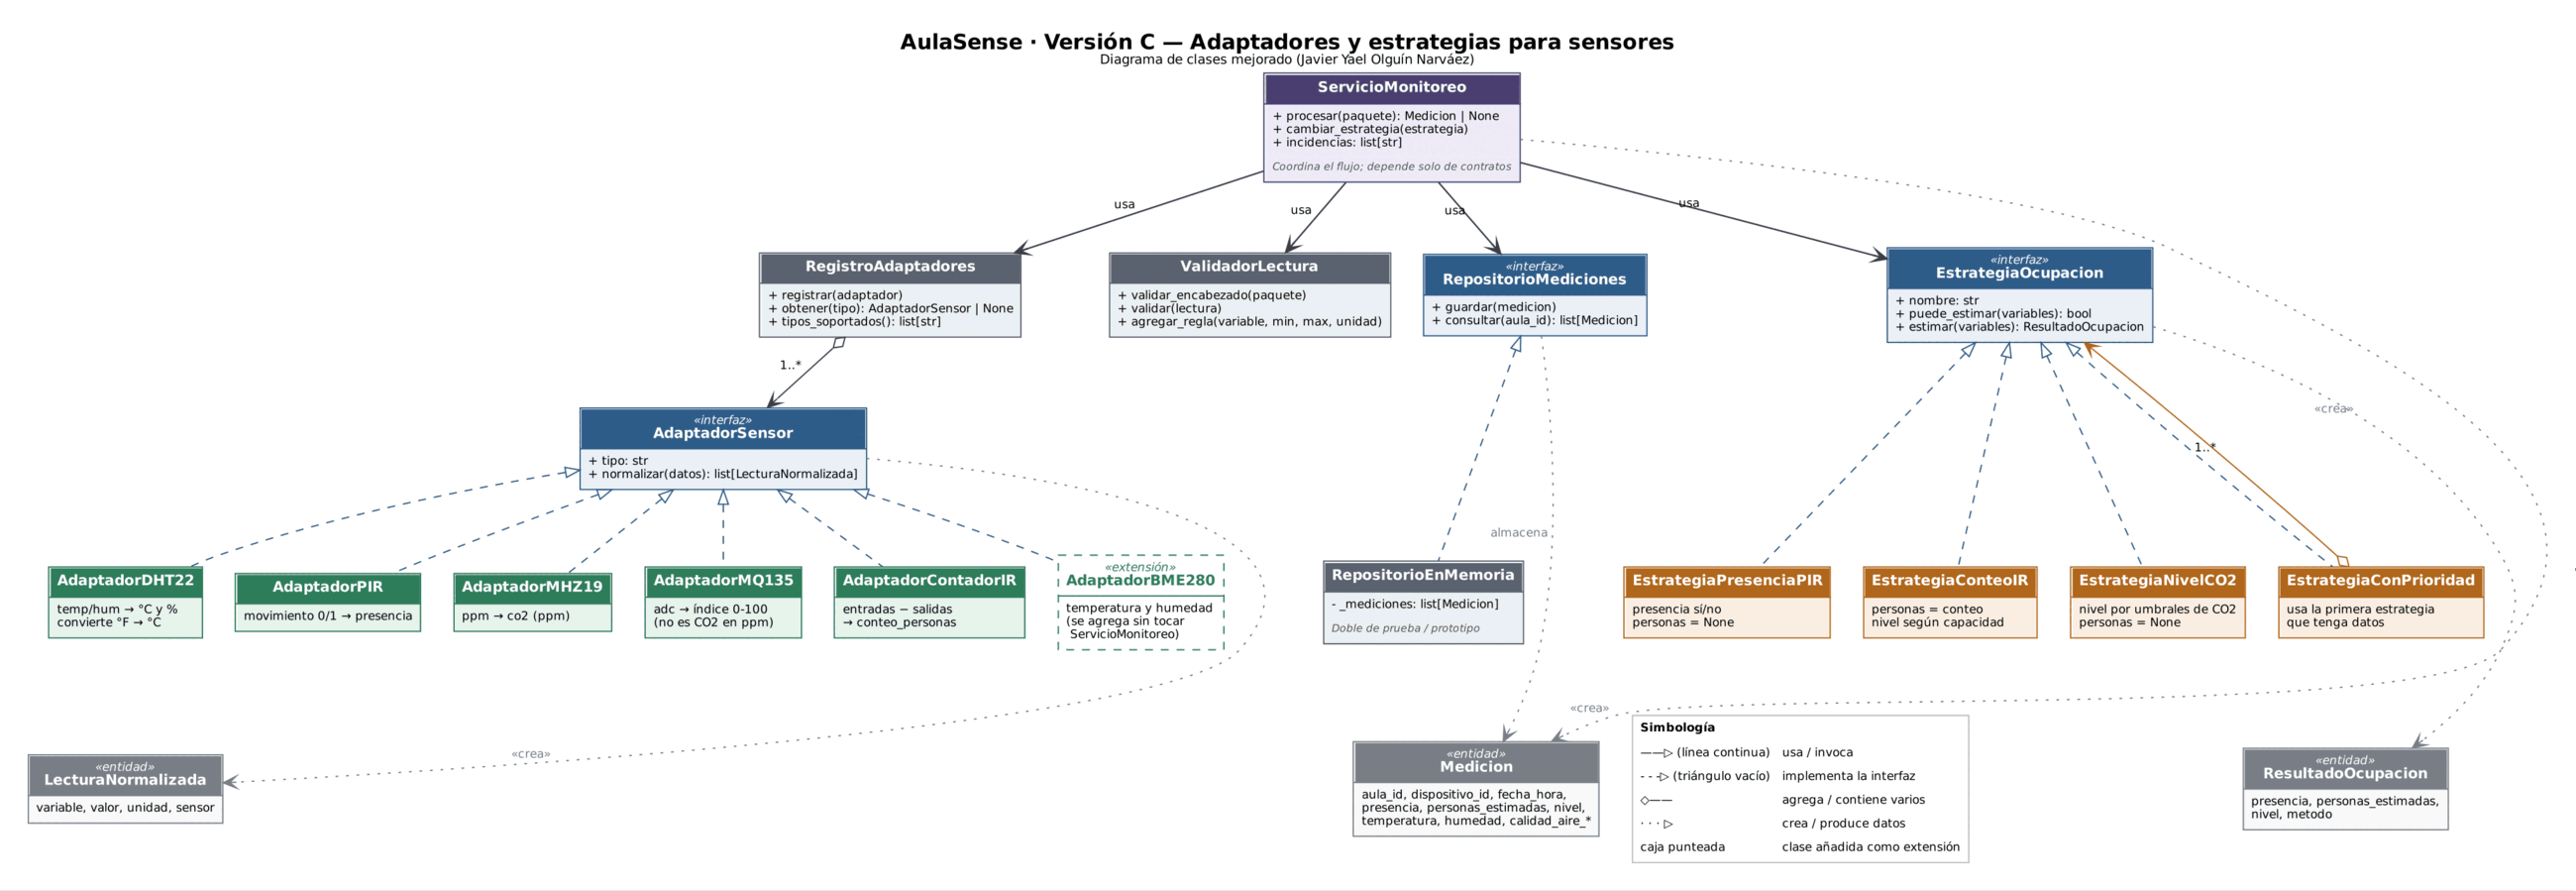

*Figura C1. Diagrama de clases de la Versión C. El archivo `diagrama_clases_javier.png` también está en esta carpeta.*

### Relaciones

| Relación | Tipo | Significado |
|---|---|---|
| `ServicioMonitoreo → RegistroAdaptadores` | Uso / dependencia | El servicio pide el adaptador adecuado según el `tipo` de cada sensor del paquete. |
| `ServicioMonitoreo → EstrategiaOcupacion` | Uso (por interfaz) | El servicio solo conoce el contrato; la estrategia concreta se **inyecta** desde fuera y se puede cambiar. |
| `ServicioMonitoreo → ValidadorLectura` | Uso | Toda lectura normalizada pasa por el validador antes de usarse. |
| `ServicioMonitoreo → RepositorioMediciones` | Uso (por interfaz) | Guarda la `Medicion`; no sabe si es memoria, archivo o base de datos. |
| `RegistroAdaptadores ◇→ AdaptadorSensor` | Agregación 1..* | El registro contiene varios adaptadores. |
| `AdaptadorDHT22, AdaptadorPIR, … ⇢ AdaptadorSensor` | Realización (implementa) | Todos cumplen el mismo contrato `normalizar(datos)`. |
| `EstrategiaPresenciaPIR, EstrategiaConteoIR, … ⇢ EstrategiaOcupacion` | Realización (implementa) | Todas cumplen `estimar(variables)`. |
| `EstrategiaConPrioridad ◇→ EstrategiaOcupacion` | Agregación 1..* (composite) | Combina varias estrategias y es, a su vez, una estrategia. |
| `AdaptadorSensor ··> LecturaNormalizada`, `EstrategiaOcupacion ··> ResultadoOcupacion`, `ServicioMonitoreo ··> Medicion` | Creación | Producen las entidades de datos que viajan entre componentes. |
| `AdaptadorBME280` (caja punteada) | Extensión | Se agrega en la sección 7 **sin modificar** `ServicioMonitoreo`. |

**Diferencia con la Versión A (capas):** aquí el foco no es separar entrada/lógica/datos/presentación, sino **aislar lo que varía (sensores y métodos de ocupación) detrás de interfaces**. Por eso el diagrama crece "hacia los lados" (nuevos adaptadores y estrategias) sin tocar el centro.

## 5. Código Python de la propuesta

### 5.1 Entidades de datos y excepción

In [1]:
from __future__ import annotations

from abc import ABC, abstractmethod
from dataclasses import dataclass
from datetime import datetime
from typing import Optional


class ErrorLectura(Exception):
    """Se lanza cuando un paquete o una lectura no cumple el formato o los rangos esperados."""


@dataclass(frozen=True)
class LecturaNormalizada:
    """Formato común que producen TODOS los adaptadores."""
    variable: str      # "temperatura", "humedad", "presencia", "co2", "indice_aire", "conteo_personas"
    valor: object      # float/int o bool (para presencia)
    unidad: str        # "°C", "%", "ppm", "índice 0-100", "personas", "bool"
    sensor: str        # modelo del sensor que la originó


@dataclass(frozen=True)
class ResultadoOcupacion:
    presencia: Optional[bool]
    personas_estimadas: Optional[int]
    nivel: str
    metodo: str

    @classmethod
    def sin_datos(cls, metodo: str) -> "ResultadoOcupacion":
        return cls(presencia=None, personas_estimadas=None, nivel="desconocido",
                   metodo=f"{metodo} (sin datos)")


@dataclass
class Medicion:
    """Registro final que se guarda (campos acordados en el documento del equipo)."""
    aula_id: str
    dispositivo_id: str
    fecha_hora: datetime
    presencia: Optional[bool]
    personas_estimadas: Optional[int]
    nivel_ocupacion: str
    metodo_ocupacion: str
    temperatura: Optional[float]
    humedad: Optional[float]
    calidad_aire_tipo: Optional[str]
    calidad_aire_valor: Optional[float]
    calidad_aire_unidad: Optional[str]


print("Entidades definidas: LecturaNormalizada, ResultadoOcupacion, Medicion")

Entidades definidas: LecturaNormalizada, ResultadoOcupacion, Medicion


### 5.2 Adaptadores de sensores (patrón Adapter)

Cada adaptador conoce **solo** el formato de su sensor. Si el firmware de un sensor cambia, se modifica únicamente su adaptador.

In [2]:
def _numero(datos: dict, clave: str, sensor: str) -> float:
    """Obtiene un número del diccionario crudo o lanza ErrorLectura."""
    if clave not in datos:
        raise ErrorLectura(f"{sensor}: falta el campo '{clave}'")
    try:
        return float(datos[clave])
    except (TypeError, ValueError):
        raise ErrorLectura(f"{sensor}: el campo '{clave}' no es numérico ({datos[clave]!r})")


class AdaptadorSensor(ABC):
    """Contrato común para cualquier sensor."""
    tipo: str = ""

    @abstractmethod
    def normalizar(self, datos: dict) -> list[LecturaNormalizada]:
        """Traduce los datos crudos del sensor a lecturas normalizadas."""


class AdaptadorDHT22(AdaptadorSensor):
    tipo = "DHT22"

    def normalizar(self, datos):
        temp = _numero(datos, "temp", self.tipo)
        hum = _numero(datos, "hum", self.tipo)
        if datos.get("escala", "C").upper() == "F":      # algunos nodos envían °F
            temp = (temp - 32) * 5 / 9
        return [
            LecturaNormalizada("temperatura", round(temp, 1), "°C", self.tipo),
            LecturaNormalizada("humedad", round(hum, 1), "%", self.tipo),
        ]


class AdaptadorPIR(AdaptadorSensor):
    tipo = "PIR"

    def normalizar(self, datos):
        mov = _numero(datos, "movimiento", self.tipo)
        if mov not in (0, 1):
            raise ErrorLectura(f"PIR: 'movimiento' debe ser 0 o 1, llegó {mov}")
        return [LecturaNormalizada("presencia", mov == 1, "bool", self.tipo)]


class AdaptadorMHZ19(AdaptadorSensor):
    tipo = "MH-Z19"

    def normalizar(self, datos):
        return [LecturaNormalizada("co2", _numero(datos, "ppm", self.tipo), "ppm", self.tipo)]


class AdaptadorMQ135(AdaptadorSensor):
    """El MQ-135 da un valor analógico relativo: se normaliza como ÍNDICE, no como CO2 en ppm."""
    tipo = "MQ-135"

    def normalizar(self, datos):
        adc = _numero(datos, "adc", self.tipo)
        indice = round(adc / 1023 * 100, 1)
        return [LecturaNormalizada("indice_aire", indice, "índice 0-100", self.tipo)]


class AdaptadorContadorIR(AdaptadorSensor):
    tipo = "ContadorIR"

    def normalizar(self, datos):
        entradas = _numero(datos, "entradas", self.tipo)
        salidas = _numero(datos, "salidas", self.tipo)
        personas = max(int(entradas - salidas), 0)
        return [LecturaNormalizada("conteo_personas", personas, "personas", self.tipo)]


class RegistroAdaptadores:
    """Catálogo tipo_de_sensor → adaptador. Agregar un sensor = registrar un adaptador."""

    def __init__(self):
        self._adaptadores: dict[str, AdaptadorSensor] = {}

    def registrar(self, adaptador: AdaptadorSensor) -> None:
        self._adaptadores[adaptador.tipo] = adaptador

    def obtener(self, tipo: str) -> Optional[AdaptadorSensor]:
        return self._adaptadores.get(tipo)

    def tipos_soportados(self) -> list[str]:
        return sorted(self._adaptadores)


print("Adaptadores definidos:", [c.tipo for c in AdaptadorSensor.__subclasses__()])

Adaptadores definidos: ['DHT22', 'PIR', 'MH-Z19', 'MQ-135', 'ContadorIR']


### 5.3 Validador de lecturas

Las reglas (rango técnico y unidad esperada) son **datos configurables**, no `if` dispersos. Los rangos son de ejemplo y se ajustarían a la hoja de datos de cada sensor.

In [3]:
class ValidadorLectura:
    REGLAS_INICIALES = {
        # variable: (mínimo, máximo, unidad esperada)
        "temperatura":     (-40, 80, "°C"),
        "humedad":         (0, 100, "%"),
        "co2":             (0, 5000, "ppm"),
        "indice_aire":     (0, 100, "índice 0-100"),
        "conteo_personas": (0, 200, "personas"),
    }

    def __init__(self):
        self._reglas = dict(self.REGLAS_INICIALES)

    def agregar_regla(self, variable, minimo, maximo, unidad):
        self._reglas[variable] = (minimo, maximo, unidad)

    def validar_encabezado(self, paquete: dict) -> None:
        for campo in ("aula_id", "dispositivo_id", "fecha_hora"):
            if not isinstance(paquete.get(campo), str) or not paquete[campo].strip():
                raise ErrorLectura(f"Paquete sin '{campo}' válido")
        try:
            datetime.fromisoformat(paquete["fecha_hora"])
        except ValueError:
            raise ErrorLectura(f"fecha_hora inválida: {paquete['fecha_hora']!r}")
        if not isinstance(paquete.get("sensores"), list):
            raise ErrorLectura("El paquete debe incluir una lista 'sensores'")

    def validar(self, lectura: LecturaNormalizada) -> None:
        if lectura.variable == "presencia":
            if not isinstance(lectura.valor, bool):
                raise ErrorLectura("presencia debe ser booleano")
            return
        if lectura.variable not in self._reglas:
            raise ErrorLectura(f"Variable sin regla de validación: {lectura.variable}")
        minimo, maximo, unidad = self._reglas[lectura.variable]
        if lectura.unidad != unidad:
            raise ErrorLectura(f"{lectura.variable}: unidad '{lectura.unidad}', se esperaba '{unidad}'")
        if not (minimo <= lectura.valor <= maximo):
            raise ErrorLectura(f"{lectura.variable}={lectura.valor} {unidad} fuera del rango técnico [{minimo}, {maximo}]")


print("Validador listo. Variables con regla:", list(ValidadorLectura.REGLAS_INICIALES))

Validador listo. Variables con regla: ['temperatura', 'humedad', 'co2', 'indice_aire', 'conteo_personas']


### 5.4 Estrategias de ocupación (patrón Strategy)

Todas reciben el mismo diccionario `variables` (nombre de variable → `LecturaNormalizada`) y devuelven un `ResultadoOcupacion`. Ninguna conoce el formato crudo de los sensores.

In [4]:
class EstrategiaOcupacion(ABC):
    nombre: str = "abstracta"
    variables_requeridas: tuple = ()

    def puede_estimar(self, variables: dict) -> bool:
        return all(v in variables for v in self.variables_requeridas)

    @abstractmethod
    def estimar(self, variables: dict) -> ResultadoOcupacion:
        """Devuelve la ocupación estimada a partir de lecturas normalizadas."""


class EstrategiaPresenciaPIR(EstrategiaOcupacion):
    """Solo sabe si hay movimiento: NO inventa un número de personas."""
    nombre = "presencia PIR"
    variables_requeridas = ("presencia",)

    def estimar(self, variables):
        if not self.puede_estimar(variables):
            return ResultadoOcupacion.sin_datos(self.nombre)
        hay = variables["presencia"].valor
        return ResultadoOcupacion(presencia=hay, personas_estimadas=None,
                                  nivel="ocupada" if hay else "vacía", metodo=self.nombre)


class EstrategiaConteoIR(EstrategiaOcupacion):
    nombre = "conteo IR"
    variables_requeridas = ("conteo_personas",)

    def __init__(self, capacidad: int = 40):
        self.capacidad = capacidad

    def estimar(self, variables):
        if not self.puede_estimar(variables):
            return ResultadoOcupacion.sin_datos(self.nombre)
        personas = int(variables["conteo_personas"].valor)
        if personas == 0:
            nivel = "vacía"
        elif personas < self.capacidad * 0.5:
            nivel = "baja"
        elif personas <= self.capacidad:
            nivel = "alta"
        else:
            nivel = "sobrecupo"
        return ResultadoOcupacion(presencia=personas > 0, personas_estimadas=personas,
                                  nivel=nivel, metodo=self.nombre)


class EstrategiaNivelCO2(EstrategiaOcupacion):
    """Estimación indirecta: el CO2 sube con la gente, pero no da un conteo exacto."""
    nombre = "nivel CO2"
    variables_requeridas = ("co2",)

    def __init__(self, umbral_medio: float = 800, umbral_alto: float = 1200):
        self.umbral_medio = umbral_medio
        self.umbral_alto = umbral_alto

    def estimar(self, variables):
        if not self.puede_estimar(variables):
            return ResultadoOcupacion.sin_datos(self.nombre)
        ppm = variables["co2"].valor
        if ppm < self.umbral_medio:
            nivel = "baja o vacía"
        elif ppm < self.umbral_alto:
            nivel = "media"
        else:
            nivel = "alta"
        return ResultadoOcupacion(presencia=None, personas_estimadas=None, nivel=nivel, metodo=self.nombre)


class EstrategiaConPrioridad(EstrategiaOcupacion):
    """Combina estrategias: usa la primera que tenga los datos necesarios."""

    def __init__(self, estrategias: list):
        self.estrategias = estrategias
        self.nombre = "prioridad[" + " > ".join(e.nombre for e in estrategias) + "]"

    def puede_estimar(self, variables):
        return any(e.puede_estimar(variables) for e in self.estrategias)

    def estimar(self, variables):
        for estrategia in self.estrategias:
            if estrategia.puede_estimar(variables):
                return estrategia.estimar(variables)
        return ResultadoOcupacion.sin_datos(self.nombre)


print("Estrategias definidas:", [c.__name__ for c in EstrategiaOcupacion.__subclasses__()])

Estrategias definidas: ['EstrategiaPresenciaPIR', 'EstrategiaConteoIR', 'EstrategiaNivelCO2', 'EstrategiaConPrioridad']


### 5.5 Repositorio y servicio coordinador

`ServicioMonitoreo` recibe sus dependencias en el constructor (**inyección de dependencias**). No contiene ningún `if tipo == "DHT22"`: todo lo específico de sensores vive en los adaptadores.

In [5]:
class RepositorioMediciones(ABC):
    @abstractmethod
    def guardar(self, medicion: Medicion) -> None: ...

    @abstractmethod
    def consultar(self, aula_id: str) -> list[Medicion]: ...


class RepositorioEnMemoria(RepositorioMediciones):
    """Implementación sencilla para el prototipo y para las pruebas."""

    def __init__(self):
        self._mediciones: list[Medicion] = []

    def guardar(self, medicion):
        self._mediciones.append(medicion)

    def consultar(self, aula_id):
        return [m for m in self._mediciones if m.aula_id == aula_id]

    def todas(self):
        return list(self._mediciones)


class ServicioMonitoreo:
    def __init__(self, registro: RegistroAdaptadores, estrategia: EstrategiaOcupacion,
                 validador: ValidadorLectura, repositorio: RepositorioMediciones):
        self.registro = registro
        self.estrategia = estrategia
        self.validador = validador
        self.repositorio = repositorio
        self.incidencias: list[str] = []

    def cambiar_estrategia(self, estrategia: EstrategiaOcupacion) -> None:
        self.estrategia = estrategia

    def procesar(self, paquete: dict) -> Optional[Medicion]:
        # 1) El encabezado inválido rechaza todo el paquete (no se guarda nada).
        try:
            self.validador.validar_encabezado(paquete)
        except ErrorLectura as e:
            self.incidencias.append(f"Paquete rechazado: {e}")
            return None

        # 2) Cada sensor se adapta y valida por separado: un sensor con error se descarta,
        #    pero los demás sensores del mismo paquete sí se aprovechan.
        variables: dict[str, LecturaNormalizada] = {}
        for sensor in paquete["sensores"]:
            tipo = sensor.get("tipo", "?")
            adaptador = self.registro.obtener(tipo)
            if adaptador is None:
                self.incidencias.append(f"{paquete['aula_id']}: sensor no soportado '{tipo}' (ignorado)")
                continue
            try:
                lecturas = adaptador.normalizar(sensor.get("datos", {}))
                for lectura in lecturas:
                    self.validador.validar(lectura)
            except ErrorLectura as e:
                self.incidencias.append(f"{paquete['aula_id']}: lectura de {tipo} descartada -> {e}")
                continue
            for lectura in lecturas:
                variables[lectura.variable] = lectura

        # 3) La estrategia configurada estima la ocupación.
        ocupacion = self.estrategia.estimar(variables)

        # 4) Se construye y guarda la medición.
        medicion = self._construir_medicion(paquete, variables, ocupacion)
        self.repositorio.guardar(medicion)
        return medicion

    @staticmethod
    def _valor(variables, nombre):
        return variables[nombre].valor if nombre in variables else None

    def _construir_medicion(self, paquete, variables, ocupacion):
        if "co2" in variables:
            aire = ("CO2", variables["co2"].valor, "ppm")
        elif "indice_aire" in variables:
            aire = ("Índice MQ-135", variables["indice_aire"].valor, "índice 0-100")
        else:
            aire = (None, None, None)
        return Medicion(
            aula_id=paquete["aula_id"],
            dispositivo_id=paquete["dispositivo_id"],
            fecha_hora=datetime.fromisoformat(paquete["fecha_hora"]),
            presencia=ocupacion.presencia,
            personas_estimadas=ocupacion.personas_estimadas,
            nivel_ocupacion=ocupacion.nivel,
            metodo_ocupacion=ocupacion.metodo,
            temperatura=self._valor(variables, "temperatura"),
            humedad=self._valor(variables, "humedad"),
            calidad_aire_tipo=aire[0],
            calidad_aire_valor=aire[1],
            calidad_aire_unidad=aire[2],
        )


# ---- Funciones de apoyo (configuración y visualización) ----
def crear_registro_basico() -> RegistroAdaptadores:
    registro = RegistroAdaptadores()
    for adaptador in (AdaptadorDHT22(), AdaptadorPIR(), AdaptadorMHZ19(),
                      AdaptadorMQ135(), AdaptadorContadorIR()):
        registro.registrar(adaptador)
    return registro


def crear_servicio(estrategia, registro=None) -> ServicioMonitoreo:
    return ServicioMonitoreo(registro or crear_registro_basico(), estrategia,
                             ValidadorLectura(), RepositorioEnMemoria())


def mostrar_mediciones(mediciones):
    f = lambda v: "—" if v is None else ("sí" if v is True else "no" if v is False else v)
    print(f"{'Aula':<7}{'Hora':<7}{'Presencia':<11}{'Personas':<10}{'Nivel':<14}{'Temp °C':<9}{'Hum %':<7}{'Calidad del aire':<34}Método")
    print("-" * 131)
    for m in mediciones:
        aire = "—" if m.calidad_aire_tipo is None else f"{m.calidad_aire_tipo}: {m.calidad_aire_valor} {m.calidad_aire_unidad}"
        print(f"{m.aula_id:<7}{m.fecha_hora:%H:%M}  {str(f(m.presencia)):<11}{str(f(m.personas_estimadas)):<10}"
              f"{m.nivel_ocupacion:<14}{str(f(m.temperatura)):<9}{str(f(m.humedad)):<7}{aire:<34}{m.metodo_ocupacion}")


print("ServicioMonitoreo listo. Sensores soportados:", crear_registro_basico().tipos_soportados())

ServicioMonitoreo listo. Sensores soportados: ['ContadorIR', 'DHT22', 'MH-Z19', 'MQ-135', 'PIR']


## 6. Prueba de funcionamiento con datos simulados

Se simulan paquetes JSON como los que enviaría el microcontrolador de cada aula. Cada aula tiene **sensores distintos**:

| Paquete | Aula | Sensores | Qué demuestra |
|---|---|---|---|
| 1 | A-101 | DHT22, PIR, MH-Z19 | Caso normal con CO₂ real en ppm. |
| 2 | B-203 | DHT22 **en °F**, ContadorIR, MQ-135 | Conversión de unidades, conteo de personas y que el MQ-135 se guarda como índice, no como CO₂. |
| 3 | C-305 | PIR, **BME280** | Sensor aún no soportado: se ignora sin detener el proceso. |
| 4 | A-101 | DHT22 con humedad **150 %**, PIR | Lectura fuera de rango: solo se descarta ese sensor. |
| 5 | ¿? | paquete **sin aula** | Encabezado inválido: se rechaza antes de guardar. |

In [6]:
paquetes_simulados = [
    {"aula_id": "A-101", "dispositivo_id": "nodo-01", "fecha_hora": "2026-10-16T09:00:00",
     "sensores": [
         {"tipo": "DHT22",  "datos": {"temp": 23.4, "hum": 48}},
         {"tipo": "PIR",    "datos": {"movimiento": 1}},
         {"tipo": "MH-Z19", "datos": {"ppm": 950}},
     ]},
    {"aula_id": "B-203", "dispositivo_id": "nodo-02", "fecha_hora": "2026-10-16T09:00:00",
     "sensores": [
         {"tipo": "DHT22",      "datos": {"temp": 75.2, "hum": 55, "escala": "F"}},
         {"tipo": "ContadorIR", "datos": {"entradas": 18, "salidas": 3}},
         {"tipo": "MQ-135",     "datos": {"adc": 410}},
     ]},
    {"aula_id": "C-305", "dispositivo_id": "nodo-03", "fecha_hora": "2026-10-16T09:05:00",
     "sensores": [
         {"tipo": "PIR",    "datos": {"movimiento": 0}},
         {"tipo": "BME280", "datos": {"temperatura_c": 22.1, "humedad_rel": 40.5, "presion_hpa": 812.3}},
     ]},
    {"aula_id": "A-101", "dispositivo_id": "nodo-01", "fecha_hora": "2026-10-16T09:10:00",
     "sensores": [
         {"tipo": "DHT22", "datos": {"temp": 24.0, "hum": 150}},   # humedad imposible
         {"tipo": "PIR",   "datos": {"movimiento": 1}},
     ]},
    {"dispositivo_id": "nodo-99", "fecha_hora": "2026-10-16T09:15:00",   # falta aula_id
     "sensores": [{"tipo": "PIR", "datos": {"movimiento": 1}}]},
]

# Estrategia para aulas con sensores mixtos: primero conteo, si no hay, PIR; si no, CO2.
estrategia_mixta = EstrategiaConPrioridad([EstrategiaConteoIR(capacidad=40),
                                           EstrategiaPresenciaPIR(),
                                           EstrategiaNivelCO2()])
servicio = crear_servicio(estrategia_mixta)

for paquete in paquetes_simulados:
    servicio.procesar(paquete)

print("MEDICIONES GUARDADAS\n")
mostrar_mediciones(servicio.repositorio.todas())
print(f"\nTotal guardadas: {len(servicio.repositorio.todas())} de {len(paquetes_simulados)} paquetes")
print("\nINCIDENCIAS REGISTRADAS")
for incidencia in servicio.incidencias:
    print(" •", incidencia)

MEDICIONES GUARDADAS

Aula   Hora   Presencia  Personas  Nivel         Temp °C  Hum %  Calidad del aire                  Método
-----------------------------------------------------------------------------------------------------------------------------------
A-101  09:00  sí         —         ocupada       23.4     48.0   CO2: 950.0 ppm                    presencia PIR
B-203  09:00  sí         15        baja          24.0     55.0   Índice MQ-135: 40.1 índice 0-100  conteo IR
C-305  09:05  no         —         vacía         —        —      —                                 presencia PIR
A-101  09:10  sí         —         ocupada       —        —      —                                 presencia PIR

Total guardadas: 4 de 5 paquetes

INCIDENCIAS REGISTRADAS
 • C-305: sensor no soportado 'BME280' (ignorado)
 • A-101: lectura de DHT22 descartada -> humedad=150.0 % fuera del rango técnico [0, 100]
 • Paquete rechazado: Paquete sin 'aula_id' válido


**Interpretación de los resultados:**

- **B-203:** el nodo envió 75.2 °F y el adaptador lo guardó como **24.0 °C**; las 18 entradas − 3 salidas dan **15 personas** (nivel "baja" para capacidad 40). La calidad del aire queda como **índice MQ-135**, no como CO₂ en ppm.
- **A-101 (09:00):** como no hay contador, la estrategia con prioridad usó **PIR**: "ocupada", pero `personas = —` porque un PIR no permite contar.
- **C-305:** el BME280 se ignoró (todavía no hay adaptador) y aun así se guardó la presencia del PIR.
- **A-101 (09:10):** se descartó la lectura del DHT22 (humedad 150 %), pero la presencia del PIR sí se guardó.
- **Paquete sin aula:** rechazado completo; no se guardó nada.

### 6.1 Cambiar la estrategia sin modificar el servicio

El **mismo** servicio y el **mismo** paquete producen resultados diferentes al intercambiar la estrategia en tiempo de ejecución:

In [7]:
paquete_a101 = {"aula_id": "A-101", "dispositivo_id": "nodo-01", "fecha_hora": "2026-10-16T11:00:00",
                "sensores": [{"tipo": "PIR", "datos": {"movimiento": 1}},
                             {"tipo": "MH-Z19", "datos": {"ppm": 1350}},
                             {"tipo": "ContadorIR", "datos": {"entradas": 37, "salidas": 2}}]}

servicio_demo = crear_servicio(EstrategiaPresenciaPIR())
for estrategia in (EstrategiaPresenciaPIR(), EstrategiaNivelCO2(), EstrategiaConteoIR(capacidad=30)):
    servicio_demo.cambiar_estrategia(estrategia)
    m = servicio_demo.procesar(paquete_a101)
    print(f"{estrategia.nombre:<15} -> presencia={m.presencia!s:<5} personas={m.personas_estimadas!s:<5} nivel={m.nivel_ocupacion}")

presencia PIR   -> presencia=True  personas=None  nivel=ocupada
nivel CO2       -> presencia=None  personas=None  nivel=alta
conteo IR       -> presencia=True  personas=35    nivel=sobrecupo


Con PIR solo se sabe que el aula está ocupada; con CO₂ se obtiene un nivel aproximado; con el contador IR se obtiene el número de personas (35) y se detecta **sobrecupo** para un aula de 30 lugares. `ServicioMonitoreo` no cambió en ninguno de los tres casos.

## 7. Extensibilidad: agregar un sensor nuevo sin modificar el servicio

Supongamos que el equipo adquiere un **BME280** (temperatura, humedad y presión). En el diseño original habría que editar `recibirLectura()` y `validarLectura()`. Aquí basta con:

1. Crear la clase `AdaptadorBME280`.
2. Registrarla en el `RegistroAdaptadores`.

`ServicioMonitoreo`, el validador y las estrategias **no se tocan**.

In [8]:
class AdaptadorBME280(AdaptadorSensor):
    tipo = "BME280"

    def normalizar(self, datos):
        # La presión no forma parte de la Medicion actual, por eso no se envía.
        return [
            LecturaNormalizada("temperatura", round(_numero(datos, "temperatura_c", self.tipo), 1), "°C", self.tipo),
            LecturaNormalizada("humedad", round(_numero(datos, "humedad_rel", self.tipo), 1), "%", self.tipo),
        ]


registro_extendido = crear_registro_basico()
registro_extendido.registrar(AdaptadorBME280())          # <- único cambio necesario
print("Sensores soportados ahora:", registro_extendido.tipos_soportados())

servicio_ext = crear_servicio(estrategia_mixta, registro=registro_extendido)
servicio_ext.procesar(paquetes_simulados[2])               # el paquete de C-305 que antes se ignoraba
print()
mostrar_mediciones(servicio_ext.repositorio.todas())
print("\nIncidencias:", servicio_ext.incidencias or "ninguna")

Sensores soportados ahora: ['BME280', 'ContadorIR', 'DHT22', 'MH-Z19', 'MQ-135', 'PIR']

Aula   Hora   Presencia  Personas  Nivel         Temp °C  Hum %  Calidad del aire                  Método
-----------------------------------------------------------------------------------------------------------------------------------
C-305  09:05  no         —         vacía         22.1     40.5   —                                 presencia PIR

Incidencias: ninguna


Ahora C-305 ya tiene temperatura y humedad, y no aparece la incidencia de "sensor no soportado".

## 8. Pruebas sencillas

Pruebas con `assert` y datos simulados (se ejecutan sin sensores ni base de datos). Cada prueba crea su propio servicio para que sean **independientes** entre sí.

In [9]:
def _paquete(*sensores, aula="T-001"):
    return {"aula_id": aula, "dispositivo_id": "nodo-test", "fecha_hora": "2026-10-16T10:00:00",
            "sensores": list(sensores)}


def prueba_dht22_normaliza_celsius():
    lecturas = AdaptadorDHT22().normalizar({"temp": 22.5, "hum": 40})
    assert lecturas[0] == LecturaNormalizada("temperatura", 22.5, "°C", "DHT22")
    assert lecturas[1].unidad == "%"


def prueba_dht22_convierte_fahrenheit():
    temp = AdaptadorDHT22().normalizar({"temp": 77, "hum": 40, "escala": "F"})[0]
    assert temp.valor == 25.0 and temp.unidad == "°C", temp


def prueba_mq135_no_se_trata_como_co2():
    m = crear_servicio(EstrategiaPresenciaPIR()).procesar(_paquete({"tipo": "MQ-135", "datos": {"adc": 512}}))
    assert m.calidad_aire_tipo == "Índice MQ-135" and m.calidad_aire_unidad != "ppm"


def prueba_pir_no_inventa_conteo():
    m = crear_servicio(EstrategiaPresenciaPIR()).procesar(_paquete({"tipo": "PIR", "datos": {"movimiento": 1}}))
    assert m.presencia is True and m.personas_estimadas is None


def prueba_conteo_ir_calcula_personas():
    m = crear_servicio(EstrategiaConteoIR(capacidad=40)).procesar(
        _paquete({"tipo": "ContadorIR", "datos": {"entradas": 25, "salidas": 5}}))
    assert m.personas_estimadas == 20 and m.nivel_ocupacion == "alta"


def prueba_cambiar_estrategia_sin_modificar_servicio():
    s = crear_servicio(EstrategiaPresenciaPIR())
    p = _paquete({"tipo": "PIR", "datos": {"movimiento": 1}},
                 {"tipo": "ContadorIR", "datos": {"entradas": 3, "salidas": 0}})
    antes = s.procesar(p).personas_estimadas
    s.cambiar_estrategia(EstrategiaConteoIR())
    despues = s.procesar(p).personas_estimadas
    assert antes is None and despues == 3


def prueba_sensor_no_soportado_no_detiene_proceso():
    s = crear_servicio(EstrategiaPresenciaPIR())
    m = s.procesar(_paquete({"tipo": "Desconocido", "datos": {}}, {"tipo": "PIR", "datos": {"movimiento": 0}}))
    assert m is not None and m.presencia is False
    assert any("no soportado" in i for i in s.incidencias)


def prueba_valor_fuera_de_rango_se_descarta():
    s = crear_servicio(EstrategiaPresenciaPIR())
    m = s.procesar(_paquete({"tipo": "DHT22", "datos": {"temp": 25, "hum": 150}}))
    assert m.humedad is None and m.temperatura is None
    assert any("fuera del rango" in i for i in s.incidencias)


def prueba_paquete_sin_aula_se_rechaza():
    s = crear_servicio(EstrategiaPresenciaPIR())
    p = _paquete({"tipo": "PIR", "datos": {"movimiento": 1}}); del p["aula_id"]
    assert s.procesar(p) is None and s.repositorio.todas() == []


def prueba_estrategia_con_prioridad_usa_respaldo():
    e = EstrategiaConPrioridad([EstrategiaConteoIR(), EstrategiaPresenciaPIR()])
    m = crear_servicio(e).procesar(_paquete({"tipo": "PIR", "datos": {"movimiento": 1}}))
    assert m.metodo_ocupacion == "presencia PIR"


def prueba_nuevo_sensor_sin_cambiar_servicio():
    registro = crear_registro_basico()
    registro.registrar(AdaptadorBME280())
    m = crear_servicio(EstrategiaPresenciaPIR(), registro).procesar(
        _paquete({"tipo": "BME280", "datos": {"temperatura_c": 21.0, "humedad_rel": 35}}))
    assert m.temperatura == 21.0 and m.humedad == 35.0


def ejecutar_pruebas(pruebas):
    superadas = 0
    for prueba in pruebas:
        try:
            prueba()
            print(f"  ✔ {prueba.__name__}")
            superadas += 1
        except AssertionError as e:
            print(f"  ✘ {prueba.__name__}  {e}")
    print(f"\n{superadas}/{len(pruebas)} pruebas superadas")


ejecutar_pruebas([
    prueba_dht22_normaliza_celsius,
    prueba_dht22_convierte_fahrenheit,
    prueba_mq135_no_se_trata_como_co2,
    prueba_pir_no_inventa_conteo,
    prueba_conteo_ir_calcula_personas,
    prueba_cambiar_estrategia_sin_modificar_servicio,
    prueba_sensor_no_soportado_no_detiene_proceso,
    prueba_valor_fuera_de_rango_se_descarta,
    prueba_paquete_sin_aula_se_rechaza,
    prueba_estrategia_con_prioridad_usa_respaldo,
    prueba_nuevo_sensor_sin_cambiar_servicio,
])

  ✔ prueba_dht22_normaliza_celsius
  ✔ prueba_dht22_convierte_fahrenheit
  ✔ prueba_mq135_no_se_trata_como_co2
  ✔ prueba_pir_no_inventa_conteo
  ✔ prueba_conteo_ir_calcula_personas
  ✔ prueba_cambiar_estrategia_sin_modificar_servicio
  ✔ prueba_sensor_no_soportado_no_detiene_proceso
  ✔ prueba_valor_fuera_de_rango_se_descarta
  ✔ prueba_paquete_sin_aula_se_rechaza
  ✔ prueba_estrategia_con_prioridad_usa_respaldo
  ✔ prueba_nuevo_sensor_sin_cambiar_servicio

11/11 pruebas superadas


## 9. Justificación técnica

### 9.1 ¿Por qué esta organización?

En AulaSense lo que **más va a cambiar** son los sensores: el prototipo empieza con una o dos aulas, pero cada aula puede tener hardware distinto y el equipo puede sustituir sensores por costo o disponibilidad. Un buen diseño aísla lo que cambia detrás de una interfaz estable. Por eso:

| Principio | Cómo se aplica |
|---|---|
| **Abierto/Cerrado (OCP)** | El sistema está *abierto* a nuevos sensores y métodos de ocupación (nuevas clases) y *cerrado* a modificaciones del `ServicioMonitoreo`. Se demostró en la sección 7. |
| **Responsabilidad única (SRP)** | Un adaptador solo traduce un sensor; una estrategia solo estima ocupación; el validador solo valida; el servicio solo coordina. |
| **Inversión de dependencias (DIP)** | `ServicioMonitoreo` depende de `AdaptadorSensor`, `EstrategiaOcupacion` y `RepositorioMediciones` (abstracciones), no de clases concretas. Las dependencias se inyectan en el constructor. |
| **Sustitución de Liskov (LSP)** | Cualquier adaptador o estrategia puede reemplazar a otro sin que el servicio lo note (sección 6.1). |
| **Patrón Adapter** | Unifica formatos heterogéneos de sensores en `LecturaNormalizada`. |
| **Patrón Strategy** (+ Composite) | Algoritmos de ocupación intercambiables; `EstrategiaConPrioridad` combina varias. |

### 9.2 Beneficios

| Criterio | Beneficio concreto en AulaSense |
|---|---|
| **Mantenimiento** | Si el firmware del DHT22 cambia el nombre de un campo, solo se edita `AdaptadorDHT22`. Si se ajusta el umbral de CO₂, solo se cambia el parámetro de `EstrategiaNivelCO2`. El cambio queda localizado. |
| **Reutilización** | Las estrategias trabajan sobre lecturas normalizadas, así que `EstrategiaNivelCO2` funciona igual con un MH-Z19 o con cualquier otro sensor de CO₂ que tenga adaptador. Los adaptadores pueden reutilizarse en otro proyecto IoT. |
| **Pruebas** | Cada adaptador se prueba con un diccionario; cada estrategia con lecturas construidas en memoria; el servicio con `RepositorioEnMemoria`. Las 11 pruebas corren sin hardware ni base de datos. |
| **Extensibilidad** | Sensor nuevo → nueva clase adaptadora + `registrar()`. Método de ocupación nuevo (p. ej. cámara o aprendizaje automático en el futuro) → nueva `EstrategiaOcupacion`. |
| **Trabajo en equipo** | El contrato `LecturaNormalizada` permite que quien programa el firmware y quien programa el servidor trabajen por separado. |

### 9.3 Comparación directa con el diseño original

| Cambio solicitado | Diseño original (`SistemaAulaSense`) | Versión C |
|---|---|---|
| Agregar sensor BME280 | Editar `recibirLectura()` y `validarLectura()` en la clase central | Crear `AdaptadorBME280` y registrarlo |
| Nodo que envía °F | Agregar conversión dentro de la clase central (y quizá en reportes) | Solo en `AdaptadorDHT22` |
| Usar conteo IR en un aula y PIR en otra | Más `if/elif` en `estimarOcupacion()` | Configurar una estrategia distinta (o `EstrategiaConPrioridad`) |
| Probar la estimación de ocupación | Requiere instanciar todo el sistema | Probar la estrategia sola con datos en memoria |

## 10. Ventajas, limitaciones y conclusiones

### Ventajas
- Agregar o reemplazar sensores no afecta al coordinador ni a las demás funciones.
- La ocupación se puede estimar con el método que permita el hardware de cada aula, y cambiarlo en ejecución.
- Las unidades y tipos se normalizan en un solo lugar, evitando errores como tratar el MQ-135 como CO₂ en ppm o inventar un conteo con un PIR.
- Un sensor con fallas no detiene el procesamiento del resto del paquete; las incidencias quedan registradas.
- Es fácil de probar: todo el comportamiento se verificó con datos simulados.

### Limitaciones
- **Más clases e interfaces:** para un prototipo de una sola aula con dos sensores, el diseño puede parecer excesivo; el beneficio aparece cuando hay variedad de hardware.
- **Dependencia del formato del firmware:** si el nodo cambia el formato del paquete JSON (no solo de un sensor), hay que actualizar el contrato acordado.
- **Calibración de estrategias:** los umbrales de CO₂ y la capacidad del aula son valores de ejemplo; deben ajustarse con datos reales. El PIR no detecta personas inmóviles y el contador IR puede acumular errores si alguien pasa en grupo.
- **Sensores duplicados:** si dos sensores reportan la misma variable (p. ej. DHT22 y BME280 midiendo temperatura), en esta versión prevalece la última lectura; haría falta una estrategia de fusión (promedio, prioridad).
- **Alcance:** esta versión se concentra en la **entrada de datos y la ocupación**; las alertas, reportes y la persistencia real se abordan mejor en las versiones A, B y D. El repositorio en memoria es solo para demostración.
- Las pruebas son con datos simulados; no sustituyen las pruebas con el hardware real.

### Relación con las versiones del equipo
La Versión C es **compatible** con las demás: en la Versión A los adaptadores vivirían dentro de la capa de recepción (`ReceptorIoT`); en la Versión B el `Ingestor` podría usar `AdaptadorSensor` antes de publicar `MedicionValidada`; en la Versión D el `ServicioRegistro` recibiría la `Medicion` ya normalizada.

### Conclusión
Separar la variabilidad de los sensores mediante **adaptadores** y la lógica de ocupación mediante **estrategias** convierte los cambios de hardware —el tipo de cambio más probable en AulaSense— en cambios **aditivos y localizados**. El `ServicioMonitoreo` queda estable, cada pieza tiene una sola responsabilidad y puede probarse de forma aislada. A cambio, se introduce un número mayor de interfaces que conviene mantener documentadas en un contrato de datos común (`LecturaNormalizada`) acordado por todo el equipo.